# 32 · Sentinel reflectance, quality masks and SQL

**Time:** 50 minutes · **Audience:** undergraduate / introductory graduate GIS and Earth science.

**By the end:** calculate NDVI and a water-related spectral index; audit missingness; query pixels with explicit units.

[Run in JupyterLite](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=32_eopf_reflectance_sql.ipynb) · [Earth lab](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/) · [Sources and licenses](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/credits.html)

Run cells from top to bottom with **Shift+Enter**. The first kernel start downloads Python WebAssembly packages.
The bundled exercises need no data-service account. Save a copy with **File → Save and Export Notebook As** before clearing browser storage.

![Four-stage workflow: STAC discovery, Zarr reading, SQL selection, linked views](assets/pipeline.svg)

In [1]:
from course import *
import numpy as np
import matplotlib.pyplot as plt
print('Ready: Python + NumPy + local teaching data')

Ready: Python + NumPy + local teaching data


**Reproducibility record.** Project: Earth in the Browser; author: course contributors;
email/organization: not supplied. Created/updated: 2026-11-21. Input: `data/eopf/`;
outputs: the figures and objects below (exports are named explicitly). Python, NumPy and
Matplotlib; SQLite where used. Initial EOPF teaching release. The acquisition is a
convenience example, not a representative sample. Missing values remain missing.

![EOPF workflow from discovery to direct maps, quality-aware analysis and server processing](assets/eopf-workflow.svg)
## 1. Read physical reflectance once

The source codec represents reflectance as packed integers with scale and offset.
The preparation script decodes `DN / 10000 - 0.1`, with zero DN missing. The bundled
arrays already contain **physical reflectance**: do not scale them again.
Four source bands are retained: blue B02, green B03, red B04 and NIR B08.
The overview averages source reflectance to 120 m; a ratio of means is not the mean
of all native-pixel ratios. A 120 m cell can mix vegetation, buildings and water.

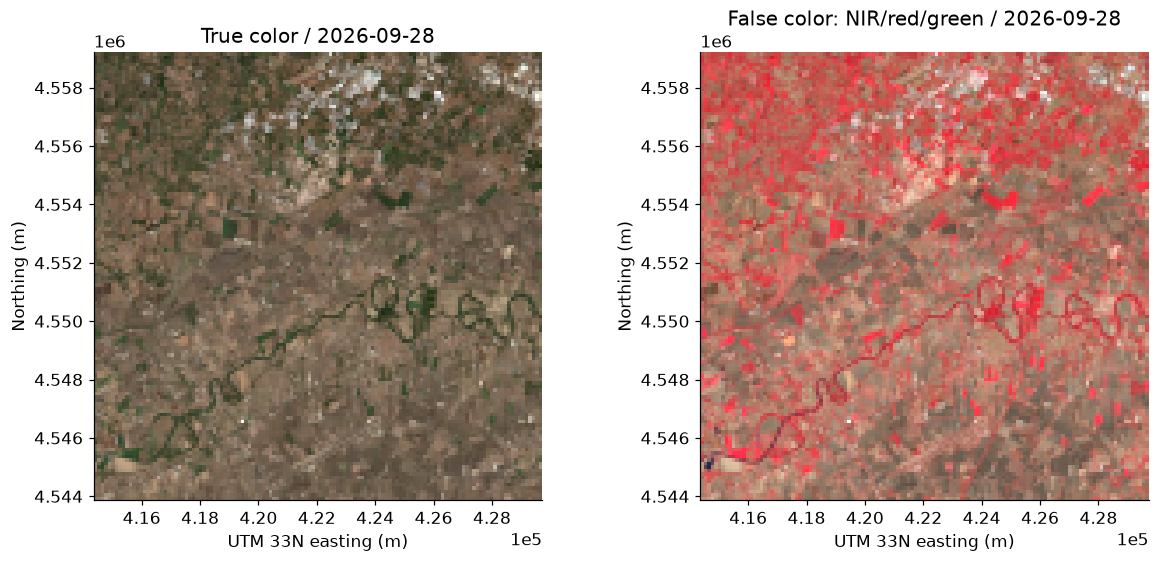

In [2]:
from eopf import load_eopf, rgb, normalized_difference
d=load_eopf(); b=d['provenance']['bounds']; extent=[b[0],b[2],b[1],b[3]]
fig,axes=plt.subplots(1,2,figsize=(11,5),layout='constrained')
for ax,bands,title in zip(axes,[('b04','b03','b02'),('b08','b04','b03')],['True color','False color: NIR/red/green']):
    ax.imshow(rgb(d,bands),extent=extent,origin='upper')
    ax.set(title=title+' / 2026-09-28',xlabel='UTM 33N easting (m)',ylabel='Northing (m)')
    ax.ticklabel_format(axis='x',style='sci',scilimits=(0,0))
plt.show()

## 2. Mask quality; retain the denominator

`clear_fraction` records the fraction of each aligned 6 × 6 block of source 20 m SCL
pixels in vegetation (4), bare/not-vegetated (5), or water (6). We require **all 36**
children accepted. This deliberately conservative teaching rule excludes clouds,
shadows and other classes; it is not a validated local quality model. No class codes
were averaged. Pixel quality is distinct from the product's cloud percentage.

NDVI = (NIR − red)/(NIR + red). Here NDWI means the **green–NIR** ratio, not the
NIR–SWIR moisture index. Neither is a measured pollution concentration or crop yield.
We also exclude negative reflectances and near-zero denominators, without clipping.

All cells: 16384 | accepted SCL: 15484 | finite NDVI: 15484


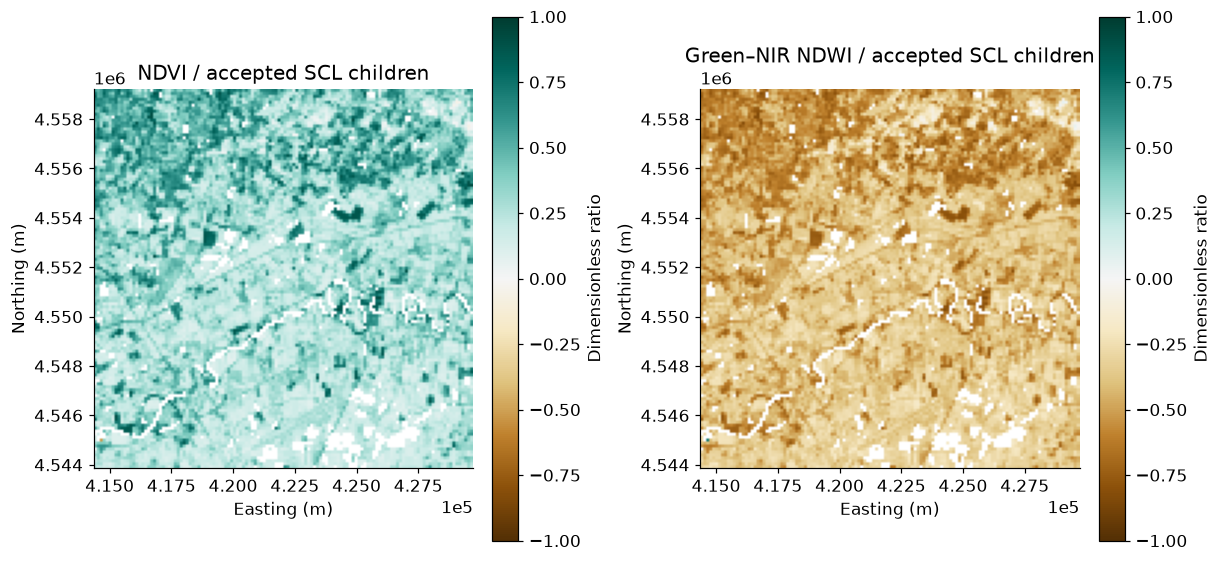

In [3]:
clear=d['clear_fraction']==1
ndvi=normalized_difference(d['b08'],d['b04'],clear)
ndwi=normalized_difference(d['b03'],d['b08'],clear)
print('All cells:',clear.size,'| accepted SCL:',int(clear.sum()),'| finite NDVI:',int(np.isfinite(ndvi).sum()))
fig,axes=plt.subplots(1,2,figsize=(11,5),layout='constrained')
for ax,value,title in zip(axes,[ndvi,ndwi],['NDVI','Green–NIR NDWI']):
    im=ax.imshow(value,extent=extent,origin='upper',vmin=-1,vmax=1,cmap='BrBG')
    ax.set(title=title+' / accepted SCL children',xlabel='Easting (m)',ylabel='Northing (m)')
    ax.ticklabel_format(axis='x',style='sci',scilimits=(0,0))
    fig.colorbar(im,ax=ax,label='Dimensionless ratio')
plt.show()

## 3. Flatten only the bounded window

Create one row per 120 m cell with a stable row/column key. Python uses SQLite;
the main course lab teaches the related Zarrita → Arrow → DuckDB-WASM pattern.
`NULL` means an excluded index, not zero vegetation. COUNT(*) and COUNT(ndvi)
therefore answer different questions. UTM coordinates below are meters, not degrees.

In [4]:
import sqlite3
con=sqlite3.connect(':memory:')
con.execute('CREATE TABLE pixels(row INTEGER,col INTEGER,x REAL,y REAL,clear REAL,ndvi REAL,PRIMARY KEY(row,col))')
records=[(r,c,float(d['x'][c]),float(d['y'][r]),float(d['clear_fraction'][r,c]),
          float(ndvi[r,c]) if np.isfinite(ndvi[r,c]) else None)
         for r in range(128) for c in range(128)]
con.executemany('INSERT INTO pixels VALUES(?,?,?,?,?,?)',records)
summary=con.execute('SELECT COUNT(*),COUNT(ndvi),AVG(ndvi) FROM pixels').fetchone()
print('Total, finite, mean NDVI:',summary)
assert summary[1]==np.isfinite(ndvi).sum()
np.testing.assert_allclose(summary[2],np.nanmean(ndvi))
print('Illustrative NDVI > 0.5 count:',con.execute('SELECT COUNT(*) FROM pixels WHERE ndvi > 0.5').fetchone()[0])

Total, finite, mean NDVI: (16384, 15484, 0.3349358816270899)
Illustrative NDVI > 0.5 count: 2885


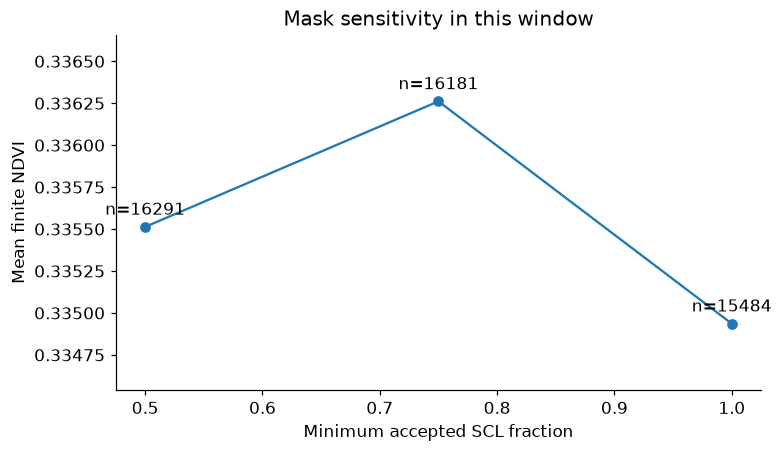

In [5]:
# Sensitivity: always report retained counts with the descriptive mean.
thresholds=np.array([0.5,0.75,1.0])
counts=[];means=[]
for threshold in thresholds:
    values=normalized_difference(d['b08'],d['b04'],d['clear_fraction']>=threshold)
    counts.append(np.isfinite(values).sum()); means.append(np.nanmean(values))
fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
ax.plot(thresholds,means,'o-');ax.set(xlabel='Minimum accepted SCL fraction',ylabel='Mean finite NDVI',title='Mask sensitivity in this window')
for x,y,n in zip(thresholds,means,counts): ax.annotate(f'n={n}',(x,y),xytext=(0,8),textcoords='offset points',ha='center')
ax.margins(y=.3);plt.show()

## Try it yourself

Change the SCL rule and NDVI threshold. Report excluded cells and explain why a large green area is not a food-security estimate.

## Check your reasoning

Spectral response depends on surface cover, atmosphere, mixtures and acquisition date. Food-security claims need crop calendars, yield validation, access and socioeconomic evidence.

## Evidence journal

Write four sentences: **what I observed; how I calculated it; what this cannot establish; what evidence I need next**.
For any figure you reuse, retain its units, date or scenario, data origin, transformations, and attribution.

## Sources and credit

- [EOPF Sentinel Zarr Explorer](https://explorer.eopf.copernicus.eu/), funded by ESA through the Copernicus Space Component programme; EOX, Development Seed and project contributors.
- [Copernicus Sentinel data legal notice](https://sentinels.copernicus.eu/documents/247904/690755/Sentinel_Data_Legal_Notice): contains modified Copernicus Sentinel data (2026). EOPF processing; course subset and repackaging.
- [Recorded source objects, checksums and transformations](https://jltobias.github.io/JupyterLite-zarr-sql-views/data/eopf/provenance.json). One 128 × 128 window of the upstream 120 m averaged overview, acquired 2026-09-28.
- [Sentinel-2 Level-2A processing and Scene Classification](https://sentiwiki.copernicus.eu/web/s2-processing)
- [zarr-sql-views, dzole0311](https://github.com/dzole0311/zarr-sql-views): inspiration for the course query-to-view architecture; this lesson uses Python SQLite.

Teaching adaptation of [dzole0311/zarr-sql-views](https://github.com/dzole0311/zarr-sql-views), ISC.
Original teaching code and prose: JupyterLite-zarr-sql-views contributors, ISC. Data keep their separate licenses.

In [6]:
print('LESSON COMPLETE: 32_eopf_reflectance_sql')

LESSON COMPLETE: 32_eopf_reflectance_sql
